# Lab 7 - Modele generatywne: VAE i GAN + sprawozdanie końcowe

## Cel zajęć

Na Lab 6 autoenkoder uczył się **kompresować i odtwarzać** dane. Dziś idziemy krok dalej: chcemy **generować nowe** obrazy, których nie było w zbiorze uczącym. Poznamy dwie najważniejsze rodziny klasycznych głębokich modeli generatywnych:
- **VAE** (Variational Autoencoder) - autoenkoder z probabilistyczną, regularną przestrzenią latentną, z której można losować,
- **GAN** (Generative Adversarial Network) - gra dwóch sieci: generatora i dyskryminatora.

Ostatnia część zajęć to **instrukcja i checklista sprawozdania końcowego**, które przesyłasz po tym laboratorium.

Po zajęciach student potrafi:
- wyjaśnić trik reparametryzacji i dwa składniki straty VAE (rekonstrukcja + KL) oraz zaimplementować VAE w Keras 3 z własnym `train_step`,
- wizualizować i interpretować przestrzeń latentną VAE, generować siatkę obrazów i interpolować między przykładami,
- zbudować DCGAN w Keras 3 (dwie sieci, dwa optymalizatory, dwie taśmy gradientów), monitorować straty G i D oraz próbki po epokach,
- rozpoznać objawy niestabilności i *mode collapse* i zmierzyć różnorodność próbek prostym klasyfikatorem,
- *(opcjonalnie)* napisać tę samą pętlę GAN w PyTorch,
- przygotować sprawozdanie końcowe zgodne z wymaganiami.

**Efekty uczenia (karta przedmiotu):** UGŁ_W01, UGŁ_W02 (modele generatywne, zaawansowane narzędzia: własne pętle uczenia), UGŁ_U01 (hipotezy - np. wpływ wagi KL $\beta$), UGŁ_U02 (usprawnienia - stabilizacja GAN), UGŁ_K01 (świadomość rozwoju dziedziny: dyfuzja, etyka deepfake).

**Powiązanie z wykładem:** W5 (VAE, GAN, minimax, mode collapse, DCGAN, FID, dyfuzja, etyka), W3 (optymalizatory, pętla treningowa w PyTorch), W2 (splot transponowany), Lab 6 (autoenkodery).

### Harmonogram (180 min)

| Czas | Blok |
|---|---|
| 0-10 min | 0. Przygotowanie środowiska, dane |
| 10-60 min | 1-2. VAE: próbkowanie, strata, trening, przestrzeń latentna, interpolacja, $\beta$ (Zadania 2.1-2.4) |
| 60-70 min | **Przerwa** |
| 70-130 min | 3. DCGAN w Keras: generator, `train_step`, monitorowanie, interpolacja, mode collapse (Zadania 3.1-3.4) |
| 130-145 min | 4. *(opcjonalnie)* GAN w PyTorch - wersja skrócona (Zadanie 4.1) |
| 145-155 min | 5. Dyfuzja i etyka - krótka dyskusja |
| 155-175 min | 6. Sprawozdanie końcowe: instrukcja, checklista, pytania |
| 175-180 min | Pytania kontrolne i podsumowanie kursu |

### Wymagania wstępne
- Lab 6: autoenkoder gęsty i konwolucyjny w Keras, `Conv2DTranspose`.
- Lab 1: `tf.GradientTape`; Lab 2/5: pętla treningowa w PyTorch.
- Rozkład normalny, wartość oczekiwana, logarytm; intuicja dywergencji KL z W5.

## 0. Przygotowanie środowiska

1. W Colab: **Środowisko wykonawcze -> Zmień typ środowiska -> T4 GPU**. GAN-y bez GPU trenują się bardzo wolno.
2. Uruchom komórki po kolei.

Zmienna `SZYBKI_TRYB`: przy `False` trenujemy na pełnych zbiorach (60 000 obrazów) z liczbą epok dającą ładne próbki. **Jeśli pracujesz bez GPU, ustaw `SZYBKI_TRYB = True`** - użyjemy 2000 obrazów i 1-2 epok; wygenerowane obrazy będą wtedy rozmytymi plamami, ale sprawdzisz, że cały kod działa.

**Ważne - Keras 3:** w Colab Keras 3 działa domyślnie na backendzie TensorFlow. Nasze własne `train_step` używają `tf.GradientTape`, więc wymagają backendu `tensorflow` (ustawiamy go jawnie przed importem). Operacje na tensorach piszemy przez `keras.ops` (np. `ops.exp`, `ops.mean`), a losowość przez `keras.random` z `SeedGenerator`.

In [9]:
import os
os.environ["KERAS_BACKEND"] = "tensorflow"   # wymagane: train_step z tf.GradientTape
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import keras
from keras import layers, ops
from scipy.stats import norm

print("TensorFlow:", tf.__version__, "| Keras:", keras.__version__, "| backend:", keras.backend.backend())
assert keras.backend.backend() == "tensorflow", "Zrestartuj sesję - potrzebny backend tensorflow"

TensorFlow: 2.21.0 | Keras: 3.13.2 | backend: tensorflow


In [10]:
gpus = tf.config.list_physical_devices("GPU")
for gpu in gpus:
    tf.config.experimental.set_memory_growth(gpu, True)
print("Dostępne GPU:", gpus if gpus else "brak - pracujesz na CPU (rozważ SZYBKI_TRYB = True)")

SEED = 42
keras.utils.set_random_seed(SEED)   # seedy Python / NumPy / TF

# Tryb szybki: True, jeśli pracujesz bez GPU (mniej epok i danych)
SZYBKI_TRYB = False

N_TRAIN = 2000 if SZYBKI_TRYB else 60000
EPOKI_VAE = 2 if SZYBKI_TRYB else 30
EPOKI_KROTKO = 1 if SZYBKI_TRYB else 10
EPOKI_GAN = 2 if SZYBKI_TRYB else 30
EPOKI_TORCH = 1 if SZYBKI_TRYB else 10
LATENT_GAN = 64 if SZYBKI_TRYB else 128
print(f"SZYBKI_TRYB={SZYBKI_TRYB}, N_TRAIN={N_TRAIN}, EPOKI_VAE={EPOKI_VAE}, EPOKI_GAN={EPOKI_GAN}")

Dostępne GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
SZYBKI_TRYB=False, N_TRAIN=60000, EPOKI_VAE=30, EPOKI_GAN=30


In [11]:
# Dane: MNIST dla VAE (piksele w [0, 1]) i Fashion-MNIST dla GAN (piksele w [-1, 1])
(xm_tr, ym_tr), (xm_te, ym_te) = keras.datasets.mnist.load_data()
x_mnist = (xm_tr[:N_TRAIN].astype("float32") / 255.0)[..., None]       # (N, 28, 28, 1)
y_mnist = ym_tr[:N_TRAIN]
x_mnist_te = (xm_te[:2000 if SZYBKI_TRYB else 10000].astype("float32") / 255.0)[..., None]
y_mnist_te = ym_te[:len(x_mnist_te)]

(xf_tr, yf_tr), (xf_te, yf_te) = keras.datasets.fashion_mnist.load_data()
x_fash = (xf_tr[:N_TRAIN].astype("float32") / 127.5 - 1.0)[..., None]  # skalowanie do [-1, 1] pod tanh
y_fash = yf_tr[:N_TRAIN]
x_fash_te = (xf_te[:2000 if SZYBKI_TRYB else 10000].astype("float32") / 127.5 - 1.0)[..., None]
y_fash_te = yf_te[:len(x_fash_te)]
KLASY_FASHION = ["T-shirt", "spodnie", "sweter", "sukienka", "płaszcz",
                 "sandał", "koszula", "sneaker", "torba", "botek"]
print("MNIST:", x_mnist.shape, x_mnist.min(), x_mnist.max(), "| Fashion:", x_fash.shape, x_fash.min(), x_fash.max())

MNIST: (60000, 28, 28, 1) 0.0 1.0 | Fashion: (60000, 28, 28, 1) -1.0 1.0


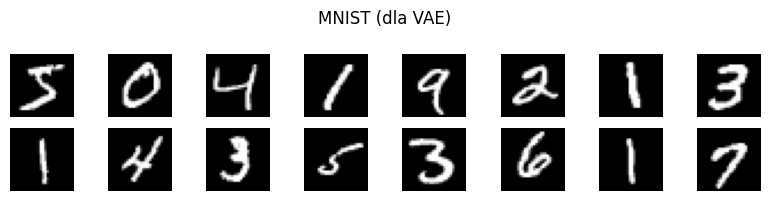

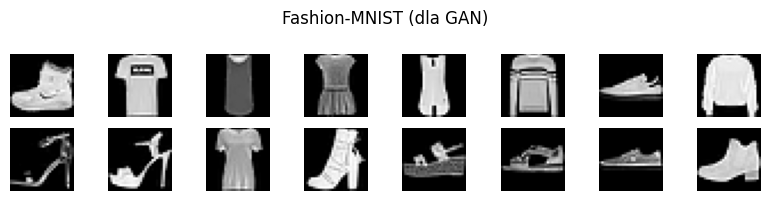

In [12]:
def plansza(obrazy, n_wierszy, n_kolumn, tytul="", zakres=(0, 1), rozmiar=1.0):
    # Rysuje obrazy (N, 28, 28[, 1]) jako jedną planszę n_wierszy x n_kolumn
    obrazy = np.asarray(obrazy).reshape(-1, 28, 28)[: n_wierszy * n_kolumn]
    fig, axes = plt.subplots(n_wierszy, n_kolumn, figsize=(rozmiar * n_kolumn, rozmiar * n_wierszy))
    for ax, im in zip(np.atleast_1d(axes).flat, obrazy):
        ax.imshow(im, cmap="gray", vmin=zakres[0], vmax=zakres[1]); ax.axis("off")
    fig.suptitle(tytul); plt.tight_layout(); plt.show()

plansza(x_mnist[:16], 2, 8, "MNIST (dla VAE)")
plansza(x_fash[:16], 2, 8, "Fashion-MNIST (dla GAN)", zakres=(-1, 1))

## 1. Od autoenkodera do modelu generatywnego

Model generatywny uczy się (jawnie lub niejawnie) **rozkładu danych** $p(\mathbf{x})$, tak aby móc losować z niego nowe próbki. Na Lab 6 widzieliśmy, że dekoder zwykłego AE potrafi zamienić punkt $\mathbf{z}$ na obraz, ale **nie wiemy, skąd losować $\mathbf{z}$**: przestrzeń latentna AE ma dziury, nierówną gęstość i nieznany kształt. Wylosowanie punktu "pomiędzy" skupieniami daje często nieczytelny kształt.

**Pomysł VAE:** wymusić, żeby rozkład kodów był bliski prostemu rozkładowi a priori $p(\mathbf{z}) = \mathcal{N}(\mathbf{0}, I)$. Wtedy generowanie jest trywialne: losujemy $\mathbf{z} \sim \mathcal{N}(\mathbf{0}, I)$ i podajemy do dekodera.

**Pomysł GAN:** nie modelujemy gęstości wprost. Generator $G(\mathbf{z})$ zamienia szum na obraz, a dyskryminator $D(\mathbf{x})$ ocenia, czy obraz jest prawdziwy. Generator uczy się "oszukiwać" dyskryminator.

| | AE (Lab 6) | VAE | GAN |
|---|---|---|---|
| Cel | rekonstrukcja | rekonstrukcja + regularny latent | realistyczne próbki |
| Enkoder | tak | tak (probabilistyczny) | brak |
| Losowanie nowych próbek | niepewne | tak, z $\mathcal{N}(0, I)$ | tak, z $\mathcal{N}(0, I)$ |
| Typowa jakość obrazów | - | lekko rozmyte | ostre |
| Stabilność treningu | wysoka | wysoka | niska (gra dwóch graczy) |

## 2. VAE - wariacyjny autoenkoder

### Teoria (W5)

Enkoder VAE nie zwraca jednego punktu, lecz **parametry rozkładu** $q_\phi(\mathbf{z}|\mathbf{x}) = \mathcal{N}(\boldsymbol{\mu}(\mathbf{x}), \operatorname{diag}\boldsymbol{\sigma}^2(\mathbf{x}))$. Dla stabilności numerycznej sieć zwraca $\log\boldsymbol{\sigma}^2$ (`z_log_var`) zamiast $\boldsymbol{\sigma}$ - może on przyjmować dowolne wartości rzeczywiste.

Uczymy maksymalizując dolne ograniczenie wiarygodności (ELBO), czyli minimalizując
$$\mathcal{L}(\mathbf{x}) = \underbrace{-\mathbb{E}_{q_\phi(\mathbf{z}|\mathbf{x})}\left[\log p_\theta(\mathbf{x}|\mathbf{z})\right]}_{\text{rekonstrukcja (BCE po pikselach)}} + \beta \cdot \underbrace{D_{KL}\left(q_\phi(\mathbf{z}|\mathbf{x}) \,\|\, \mathcal{N}(\mathbf{0}, I)\right)}_{\text{regularyzacja latentu}}$$
gdzie standardowy VAE ma $\beta = 1$. Dla rozkładów normalnych KL ma postać zamkniętą:
$$D_{KL} = -\frac{1}{2}\sum_{j=1}^{d}\left(1 + \log\sigma_j^2 - \mu_j^2 - \sigma_j^2\right).$$

**Trik reparametryzacji:** losowanie $\mathbf{z} \sim \mathcal{N}(\boldsymbol\mu, \boldsymbol\sigma^2)$ nie jest różniczkowalne względem $\boldsymbol\mu, \boldsymbol\sigma$. Przepisujemy je jako
$$\mathbf{z} = \boldsymbol{\mu} + \boldsymbol{\sigma} \odot \boldsymbol{\epsilon}, \quad \boldsymbol{\epsilon} \sim \mathcal{N}(\mathbf{0}, I), \quad \boldsymbol\sigma = \exp\left(\tfrac{1}{2}\log\boldsymbol\sigma^2\right).$$
Losowość jest teraz w $\boldsymbol\epsilon$ (stała z punktu widzenia gradientu), a gradient płynie przez $\boldsymbol\mu$ i $\boldsymbol\sigma$.

**Intuicja dwóch składników:** sama rekonstrukcja dałaby zwykły AE (σ -> 0, kody rozrzucone byle jak). Sam KL ściągnąłby wszystkie kody do $\mathcal{N}(0, I)$ i dekoder nie miałby żadnej informacji. Kompromis daje przestrzeń jednocześnie **informatywną i regularną**.

### Zadanie 2.1 - warstwa próbkowania (trik reparametryzacji)

Uzupełnij metodę `call` warstwy `Sampling`: na wejściu para `(z_mean, z_log_var)`, na wyjściu $\mathbf{z} = \boldsymbol\mu + \exp(0.5 \log\boldsymbol\sigma^2)\odot\boldsymbol\epsilon$.

**Wymagania Keras 3:** używaj `keras.ops` (`ops.exp`, `ops.shape`) oraz `keras.random.normal(shape, seed=self.seed_generator)`. Nie używaj `tf.random.normal` ani `K.random_normal` z Keras 2 - działają inaczej lub nie istnieją.

**Kryteria sukcesu:** test w komórce poniżej - dla `z_mean = 3`, `z_log_var = log(0.25)` średnia próbek ok. 3.0, odchylenie standardowe ok. 0.5.

In [13]:
class Sampling(layers.Layer):

    def __init__(self, seed=SEED, **kwargs):
        super().__init__(**kwargs)
        self.seed_generator = keras.random.SeedGenerator(seed)

    def call(self, inputs):
        z_mean, z_log_var = inputs
        eps=keras.random.normal(ops.shape(z_mean),seed=self.seed_generator)
        return z_mean+ops.exp(.5*z_log_var)*eps

# Test warstwy
mu_t = np.full((20000, 2), 3.0, dtype="float32")
lv_t = np.full((20000, 2), np.log(0.25), dtype="float32")
z_t = ops.convert_to_numpy(Sampling()([mu_t, lv_t]))
print("średnia:", z_t.mean(0).round(3), "| odch. std.:", z_t.std(0).round(3), "(oczekiwane ok. 3.0 i 0.5)")

średnia: [3.008 2.997] | odch. std.: [0.502 0.499] (oczekiwane ok. 3.0 i 0.5)


### Enkoder i dekoder VAE

Architektura konwolucyjna, jak CAE z Lab 6, ale enkoder ma **trzy wyjścia**: `z_mean`, `z_log_var` i wylosowane `z`. Latent ma tylko **2 wymiary**, żeby dało się go narysować. Dekoder kończy się `sigmoid` (piksele w $[0,1]$, strata BCE).

In [14]:
LATENT_VAE = 2

def zbuduj_enkoder_vae(latent_dim=LATENT_VAE):
    wej = keras.Input(shape=(28, 28, 1))
    h = layers.Conv2D(32, 3, strides=2, padding="same", activation="relu")(wej)
    h = layers.Conv2D(64, 3, strides=2, padding="same", activation="relu")(h)
    h = layers.Flatten()(h)
    h = layers.Dense(16, activation="relu")(h)
    z_mean = layers.Dense(latent_dim, name="z_mean")(h)
    z_log_var = layers.Dense(latent_dim, name="z_log_var")(h)
    z = Sampling(name="z")([z_mean, z_log_var])
    return keras.Model(wej, [z_mean, z_log_var, z], name="vae_enkoder")

def zbuduj_dekoder_vae(latent_dim=LATENT_VAE):
    wej = keras.Input(shape=(latent_dim,))
    h = layers.Dense(7 * 7 * 64, activation="relu")(wej)
    h = layers.Reshape((7, 7, 64))(h)
    h = layers.Conv2DTranspose(64, 3, strides=2, padding="same", activation="relu")(h)
    h = layers.Conv2DTranspose(32, 3, strides=2, padding="same", activation="relu")(h)
    wyj = layers.Conv2D(1, 3, padding="same", activation="sigmoid")(h)
    return keras.Model(wej, wyj, name="vae_dekoder")

enc_vae = zbuduj_enkoder_vae()
dec_vae = zbuduj_dekoder_vae()
enc_vae.summary()

Model: "vae_enkoder"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 28, 28, 1) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 14, 14,    │        320 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 7, 7, 64)  │     18,496 │ conv2d[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten (Flatten)   │ (None, 3136)      │          0 │ conv2d_1[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 16)        │     50,192 │ flatten[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_mean (Dense)      │ (None, 2)         │         34 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_log_var (Dense)   │ (None, 2)         │         34 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z (Sampling)        │ (None, 2)         │          0 │ z_mean[0][0],     │
│                     │                   │            │ z_log_var[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 69,076 (269.83 KB)

 Trainable params: 69,076 (269.83 KB)

 Non-trainable params: 0 (0.00 B)

### Model VAE z własnym `train_step` (Keras 3)

Strata VAE zależy od wewnętrznych tensorów (`z_mean`, `z_log_var`), więc nie pasuje do schematu `compile(loss=...)`. Nadpisujemy `train_step` w podklasie `keras.Model`. Wzorzec Keras 3 (backend TF):

1. `with tf.GradientTape() as tape:` - przebieg w przód i policzenie straty,
2. `tape.gradient(strata, self.trainable_weights)`,
3. `self.optimizer.apply_gradients(zip(grads, self.trainable_weights))`,
4. aktualizacja metryk-śledzących (`keras.metrics.Mean`) i zwrócenie słownika `{nazwa: wartość}`.

**Pułapki Keras 3 vs Keras 2 (często w starych tutorialach):**
- nie ma `self.compiled_loss` / `self.compiled_metrics` w starym stylu - używamy własnych `keras.metrics.Mean`,
- metryki muszą być zwrócone przez właściwość `metrics`, żeby Keras resetował je na początku każdej epoki,
- `fit(x)` bez `y` przekazuje do `train_step` same dane albo krotkę - obsługujemy oba przypadki,
- operacje matematyczne przez `keras.ops`, nie `K.` (moduł `keras.backend` z Keras 2 jest okrojony).

**Skala straty:** rekonstrukcję **sumujemy po pikselach** (784 składniki), a KL po wymiarach latentu, i dopiero potem uśredniamy po batchu. Jeśli uśrednisz BCE po pikselach, rekonstrukcja będzie ok. 784 razy "słabsza" od KL i VAE wygeneruje same rozmyte średnie (*posterior collapse*).

### Zadanie 2.2 - strata VAE w `train_step`

W metodzie `oblicz_straty` uzupełnij:
- `rec_loss` - BCE między `data` a `rekonstrukcja`, zsumowana po osiach (1, 2) (kanał już redukuje `keras.losses.binary_crossentropy`), uśredniona po batchu,
- `kl_loss` - wzór na $D_{KL}$ z teorii, zsumowany po wymiarach latentu (oś 1), uśredniony po batchu.

Metodę `oblicz_straty` wykorzystują zarówno `train_step`, jak i `test_step` (walidacja).

**Kryteria sukcesu:** trening startuje, `kl_loss` jest dodatnia, `loss` = `rec_loss` + β·`kl_loss` maleje. W pełnym trybie po 30 epokach `loss` ok. 150-160, `kl_loss` ok. 5-7.

In [15]:
class VAE(keras.Model):
    def __init__(self, enkoder, dekoder, beta=1.0, **kwargs):
        super().__init__(**kwargs)
        self.enkoder, self.dekoder, self.beta = enkoder, dekoder, beta
        # Metryki-śledzące: średnia bieżąca w epoce
        self.loss_tracker = keras.metrics.Mean(name="loss")
        self.rec_tracker = keras.metrics.Mean(name="rec_loss")
        self.kl_tracker = keras.metrics.Mean(name="kl_loss")

    @property
    def metrics(self):

        return [self.loss_tracker, self.rec_tracker, self.kl_tracker]

    def call(self, x, training=False):

        _, _, z = self.enkoder(x, training=training)
        return self.dekoder(z, training=training)

    def oblicz_straty(self, data, training):
        z_mean, z_log_var, z = self.enkoder(data, training=training)
        rekonstrukcja = self.dekoder(z, training=training)
        bce=keras.losses.binary_crossentropy(data,rekonstrukcja)
        rec_loss=ops.mean(ops.sum(bce,axis=(1,2)))
        kl_loss=ops.mean(ops.sum(-.5*(1+z_log_var-ops.square(z_mean)-ops.exp(z_log_var)),axis=1))
        return rec_loss + self.beta * kl_loss, rec_loss, kl_loss

    def _aktualizuj(self, total, rec, kl):
        self.loss_tracker.update_state(total)
        self.rec_tracker.update_state(rec)
        self.kl_tracker.update_state(kl)
        return {m.name: m.result() for m in self.metrics}

    def train_step(self, data):
        if isinstance(data, (tuple, list)):
            data = data[0]
        with tf.GradientTape() as tape:
            total, rec, kl = self.oblicz_straty(data, training=True)
        grads = tape.gradient(total, self.trainable_weights)
        self.optimizer.apply_gradients(zip(grads, self.trainable_weights))
        return self._aktualizuj(total, rec, kl)

    def test_step(self, data):
        if isinstance(data, (tuple, list)):
            data = data[0]
        total, rec, kl = self.oblicz_straty(data, training=False)
        return self._aktualizuj(total, rec, kl)

In [16]:
vae = VAE(enc_vae, dec_vae, beta=1.0)
vae.compile(optimizer=keras.optimizers.Adam(1e-3))

t0 = time.time()
hist_vae = vae.fit(x_mnist, epochs=EPOKI_VAE, batch_size=128,
                   validation_data=(x_mnist_te, x_mnist_te), verbose=2)
print(f"Czas treningu VAE: {time.time() - t0:.1f} s")

Epoch 1/30
469/469 - 24s - 51ms/step - kl_loss: 2.8174 - loss: 216.4298 - rec_loss: 213.6123 - val_kl_loss: 3.2933 - val_loss: 193.8057 - val_rec_loss: 190.5123
Epoch 2/30
469/469 - 4s - 8ms/step - kl_loss: 3.2962 - loss: 190.1094 - rec_loss: 186.8132 - val_kl_loss: 3.4420 - val_loss: 185.9267 - val_rec_loss: 182.4847
Epoch 3/30
469/469 - 3s - 7ms/step - kl_loss: 5.2987 - loss: 174.3476 - rec_loss: 169.0490 - val_kl_loss: 5.9494 - val_loss: 168.2092 - val_rec_loss: 162.2599
Epoch 4/30
469/469 - 3s - 7ms/step - kl_loss: 6.0588 - loss: 166.1774 - rec_loss: 160.1187 - val_kl_loss: 6.1533 - val_loss: 164.1832 - val_rec_loss: 158.0298
Epoch 5/30
469/469 - 4s - 8ms/step - kl_loss: 6.2094 - loss: 162.9957 - rec_loss: 156.7863 - val_kl_loss: 6.2832 - val_loss: 161.6951 - val_rec_loss: 155.4118
Epoch 6/30
469/469 - 4s - 8ms/step - kl_loss: 6.3419 - loss: 160.9617 - rec_loss: 154.6199 - val_kl_loss: 6.4391 - val_loss: 159.9558 - val_rec_loss: 153.5167
Epoch 7/30
469/469 - 3s - 7ms/step - kl_loss

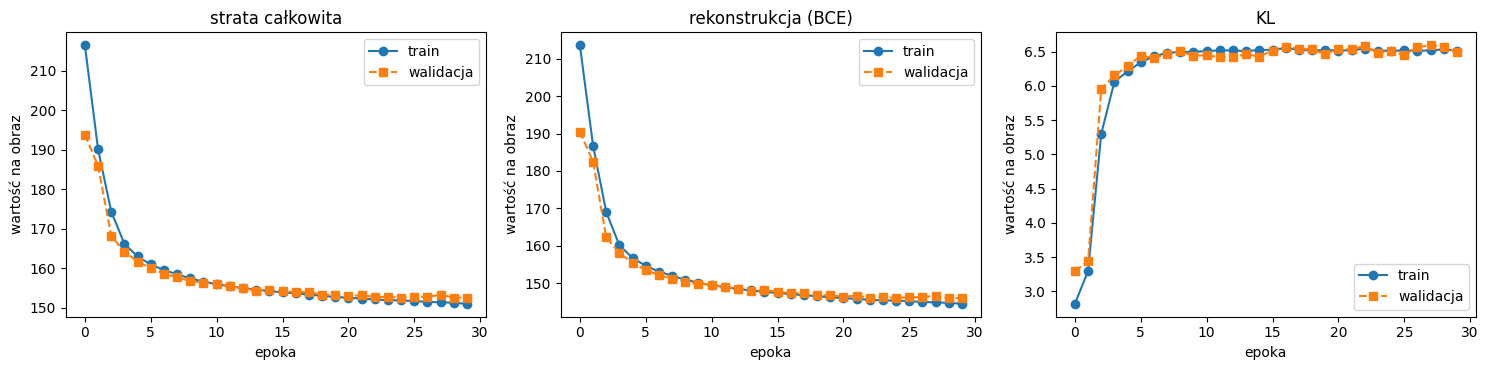

In [17]:

h = hist_vae.history
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
for a, klucz, tyt in zip(ax, ["loss", "rec_loss", "kl_loss"], ["strata całkowita", "rekonstrukcja (BCE)", "KL"]):
    a.plot(h[klucz], "o-", label="train")
    a.plot(h["val_" + klucz], "s--", label="walidacja")
    a.set_title(tyt); a.set_xlabel("epoka"); a.set_ylabel("wartość na obraz"); a.legend()
plt.tight_layout(); plt.show()

**Co obserwować:** KL na początku zwykle **rośnie** (enkoder zaczyna kodować informację, odchodząc od $\mathcal{N}(0, I)$), a potem się stabilizuje; rekonstrukcja monotonicznie maleje. To naturalna "negocjacja" między dwoma składnikami. Jeśli KL spada do ok. 0 i tam zostaje - latent przestał nieść informację (*posterior collapse*), sprawdź skalę `rec_loss`.

### Przestrzeń latentna VAE i generowanie z siatki

Rysujemy `z_mean` dla obrazów testowych (bez losowania - to "środek" kodu obrazu). Następnie dekodujemy regularną siatkę punktów. Siatkę budujemy na **kwantylach rozkładu normalnego** (`norm.ppf`), bo a priori $\mathbf{z} \sim \mathcal{N}(0, I)$ - dzięki temu punkty są gęściej tam, gdzie leży większość masy prawdopodobieństwa.

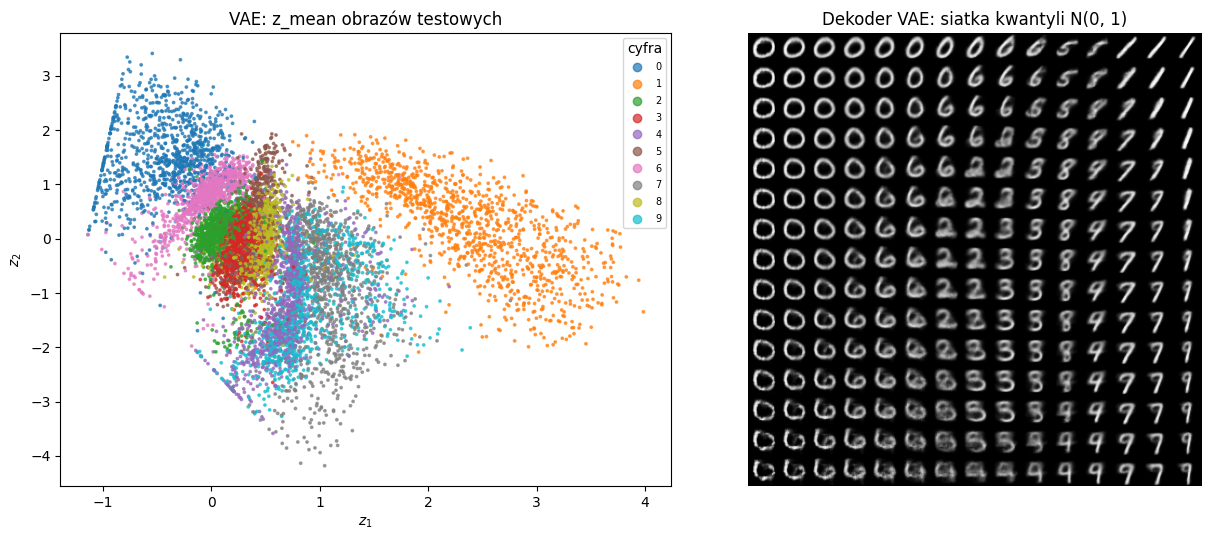

średnia z_mean: [ 0.59 -0.08] | odch. std.: [0.82 1.08] | średnie sigma: [0.034 0.065]


In [18]:
z_mean_te, z_log_var_te, _ = enc_vae.predict(x_mnist_te, verbose=0)
fig, ax = plt.subplots(1, 2, figsize=(13, 5.5))
sc = ax[0].scatter(z_mean_te[:, 0], z_mean_te[:, 1], c=y_mnist_te, cmap="tab10", s=3, alpha=0.7)
ax[0].legend(*sc.legend_elements(), title="cyfra", fontsize=7)
ax[0].set_xlabel("$z_1$"); ax[0].set_ylabel("$z_2$"); ax[0].set_title("VAE: z_mean obrazów testowych")

n = 15
siatka_z = np.array([[norm.ppf(a), norm.ppf(b)]
                     for b in np.linspace(0.95, 0.05, n) for a in np.linspace(0.05, 0.95, n)], dtype="float32")
gen = dec_vae.predict(siatka_z, verbose=0).reshape(n, n, 28, 28)
ax[1].imshow(gen.transpose(0, 2, 1, 3).reshape(n * 28, n * 28), cmap="gray")
ax[1].set_title("Dekoder VAE: siatka kwantyli N(0, 1)"); ax[1].axis("off")
plt.tight_layout(); plt.show()
print("średnia z_mean:", z_mean_te.mean(0).round(2), "| odch. std.:", z_mean_te.std(0).round(2),
      "| średnie sigma:", np.exp(0.5 * z_log_var_te).mean(0).round(3))

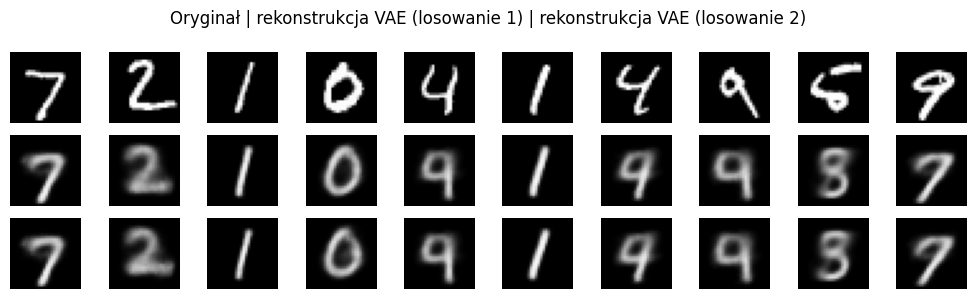

średnia różnica między dwoma losowaniami: 0.013107662089169025


In [19]:

rek_1 = vae.predict(x_mnist_te[:10], verbose=0)
rek_2 = vae.predict(x_mnist_te[:10], verbose=0)
plansza(np.concatenate([x_mnist_te[:10], rek_1, rek_2]), 3, 10,
        "Oryginał | rekonstrukcja VAE (losowanie 1) | rekonstrukcja VAE (losowanie 2)")
print("średnia różnica między dwoma losowaniami:", float(np.abs(rek_1 - rek_2).mean()))

**Typowe błędy przy VAE:**
- strata rekonstrukcji uśredniona zamiast zsumowana po pikselach - KL dominuje, latent "zapada się",
- znak w KL (strata ujemna i rosnąca),
- `ops.exp(z_log_var)` zamiast `ops.exp(0.5 * z_log_var)` w próbkowaniu,
- wizualizacja `z` (losowe) zamiast `z_mean` - wykres jest "zaszumiony",
- brak właściwości `metrics` - wartości w logach kumulują się między epokami zamiast być resetowane.

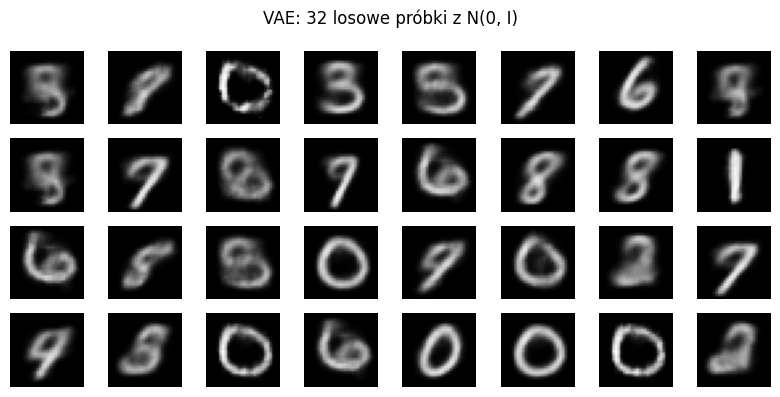

In [20]:

z_los = np.random.default_rng(SEED).normal(size=(32, LATENT_VAE)).astype("float32")
plansza(dec_vae.predict(z_los, verbose=0), 4, 8, "VAE: 32 losowe próbki z N(0, I)")

### Zadanie 2.3 - interpolacja: przestrzeń pikseli vs przestrzeń latentna

Weź dwa obrazy testowe różnych cyfr (np. pierwsze wystąpienie 1 i 8: `x_a`, `x_b`).
1. **Interpolacja w pikselach:** $(1-t)\mathbf{x}_a + t\,\mathbf{x}_b$ dla 10 wartości $t \in [0, 1]$.
2. **Interpolacja w latencie:** zakoduj oba obrazy (`z_mean`), interpoluj $\mathbf{z}_t = (1-t)\mathbf{z}_a + t\,\mathbf{z}_b$ i zdekoduj.
3. Narysuj oba wiersze (zmienne `wiersz_piksele`, `wiersz_latent` - tablice `(10, 28, 28)`).

**Kryteria sukcesu:** w pikselach widać "nałożenie dwóch obrazów" (przenikanie), w latencie - stopniową zmianę kształtu, każdy obraz pośredni wygląda jak (jakaś) cyfra.

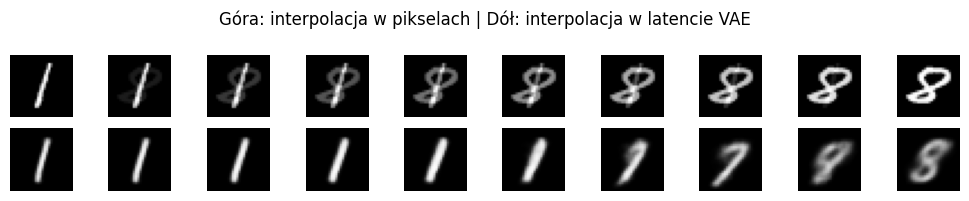

In [21]:
ts = np.linspace(0, 1, 10)
x_a = x_mnist_te[np.argmax(y_mnist_te == 1)]
x_b = x_mnist_te[np.argmax(y_mnist_te == 8)]
wiersz_piksele=np.asarray([(1-t)*x_a+t*x_b for t in ts])
za=enc_vae.predict(x_a[None,...],verbose=0)[0][0]
zb=enc_vae.predict(x_b[None,...],verbose=0)[0][0]
z_inter=np.asarray([(1-t)*za+t*zb for t in ts],dtype=np.float32)
wiersz_latent=dec_vae.predict(z_inter,verbose=0)
if wiersz_piksele is not None:
    plansza(np.concatenate([np.reshape(wiersz_piksele, (10, 28, 28)), np.reshape(wiersz_latent, (10, 28, 28))]),
            2, 10, "Góra: interpolacja w pikselach | Dół: interpolacja w latencie VAE")

### Zadanie 2.4 - hipoteza: wpływ wagi KL ($\beta$)

**Hipoteza (UGŁ_U01):** *zwiększenie $\beta$ poprawia regularność przestrzeni latentnej (kody bliższe $\mathcal{N}(0,I)$) kosztem jakości rekonstrukcji; zmniejszenie $\beta$ działa odwrotnie.*

1. Wytrenuj trzy VAE (nowe enkodery i dekodery!) z $\beta \in \{0.1, 1, 4\}$ przez `EPOKI_KROTKO` epok.
2. Dla każdego zapisz w `wyniki_beta` (lista słowników): `beta`, końcowe `rec_loss`, `kl_loss` (z historii) oraz odchylenie standardowe `z_mean` na teście.
3. Narysuj trzy wykresy przestrzeni latentnej obok siebie.
4. Napisz 2-3 zdania wniosku: czy hipoteza się potwierdziła?

**Wskazówka:** ponieważ `rec_loss` jest sumą po 784 pikselach, $\beta = 4$ to wciąż umiarkowana regularyzacja; przy $\beta \to 0$ VAE zbliża się do zwykłego AE.

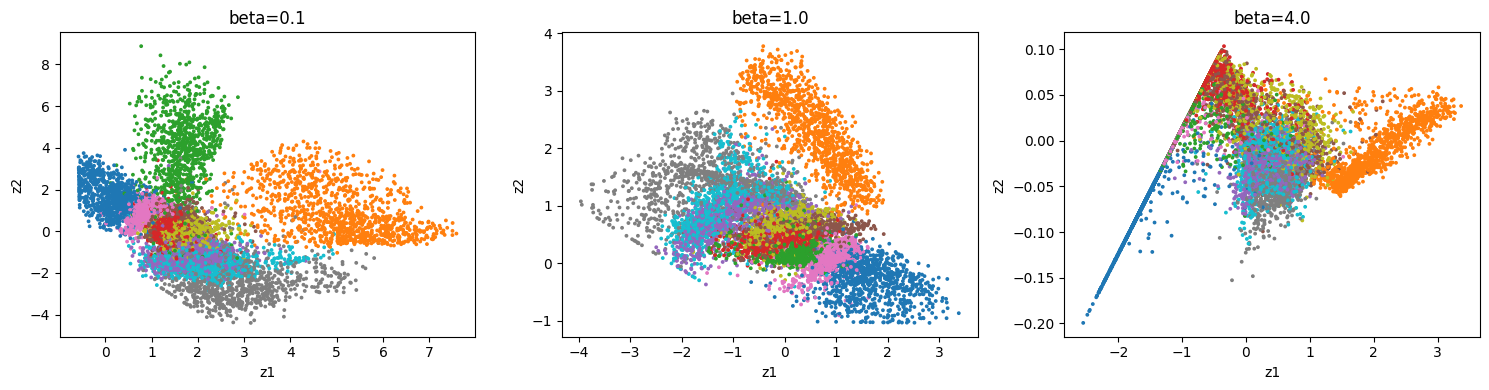

,beta,rec_loss,kl_loss,std_z_mean
0,0.1,146.362,13.021,1.632
1,1.0,148.537,6.367,0.933
2,4.0,173.406,2.394,0.549


In [22]:
wyniki_beta = []
fig,axes=plt.subplots(1,3,figsize=(15,4))
for ax,beta in zip(axes,[.1,1.,4.]):
    enc_b=zbuduj_enkoder_vae()
    dec_b=zbuduj_dekoder_vae()
    vae_b=VAE(enc_b,dec_b,beta=beta)
    vae_b.compile(optimizer=keras.optimizers.Adam(1e-3))
    h_b=vae_b.fit(x_mnist,epochs=EPOKI_KROTKO,batch_size=128,verbose=0)
    zm_b=enc_b.predict(x_mnist_te,verbose=0)[0]
    wyniki_beta.append({"beta":beta,"rec_loss":h_b.history['rec_loss'][-1],
                        "kl_loss":h_b.history['kl_loss'][-1],"std_z_mean":zm_b.std(axis=0).mean()})
    ax.scatter(zm_b[:,0],zm_b[:,1],c=y_mnist_te,cmap="tab10",s=3)
    ax.set_title(f"beta={beta}");ax.set_xlabel("z1");ax.set_ylabel("z2")
plt.tight_layout();plt.show()
display(pd.DataFrame(wyniki_beta).round(3))

## 3. GAN - generatywne sieci przeciwstawne (DCGAN)

### Teoria (W5)

Dwie sieci grają w grę o sumie zerowej:
- **generator** $G_\theta(\mathbf{z})$, $\mathbf{z} \sim \mathcal{N}(0, I)$ - tworzy obraz,
- **dyskryminator** $D_\psi(\mathbf{x}) \in (0,1)$ - prawdopodobieństwo, że obraz jest prawdziwy.

$$\min_G \max_D \; V(D, G) = \mathbb{E}_{\mathbf{x}\sim p_{dane}}[\log D(\mathbf{x})] + \mathbb{E}_{\mathbf{z}\sim p(\mathbf{z})}[\log(1 - D(G(\mathbf{z})))].$$

W optimum (Goodfellow i in., 2014) $p_G = p_{dane}$ i $D \equiv 1/2$. W praktyce trenujemy **naprzemiennie**:
1. **Krok D:** maksymalizuj $\log D(\mathbf{x}) + \log(1 - D(G(\mathbf{z})))$, czyli BCE z etykietą 1 dla prawdziwych i 0 dla fałszywych.
2. **Krok G:** zamiast minimalizować $\log(1 - D(G(\mathbf{z})))$ (gradient zanika, gdy D łatwo wygrywa), **maksymalizujemy $\log D(G(\mathbf{z}))$** - tzw. *non-saturating loss*. W kodzie: BCE fałszywych obrazów z etykietą **1**.

Dyskryminator zwraca **logity** (bez sigmoidy), a strata to `BinaryCrossentropy(from_logits=True)` - numerycznie stabilniej.

**Zasady DCGAN (Radford i in., 2015):** splot ze stride zamiast poolingu, `Conv2DTranspose` w G, BatchNorm w G, `LeakyReLU(0.2)` w D, `tanh` na wyjściu G (dlatego dane w $[-1, 1]$), Adam z lr = 2e-4 i $\beta_1 = 0.5$.

**Typowe problemy:**
- **mode collapse** - G produkuje tylko kilka rodzajów obrazów, które dobrze oszukują D,
- **niestabilność / oscylacje** - straty skaczą, jakość próbek pogarsza się po pewnym czasie,
- **D za silny** - strata D -> 0, gradient dla G zanika. Pomaga: *label smoothing* (etykieta 0.9 zamiast 1 dla prawdziwych), Dropout w D, mniejsze lr D.

**Ważne:** strata G i D **nie mówi**, czy obrazy są dobre (to gra, a nie minimalizacja jednej funkcji). Jakość oceniamy wzrokowo i metrykami typu FID.

In [23]:
def zbuduj_dyskryminator():
    wej = keras.Input(shape=(28, 28, 1))
    h = layers.Conv2D(64, 4, strides=2, padding="same")(wej)          # 14x14x64
    h = layers.LeakyReLU(negative_slope=0.2)(h)
    h = layers.Conv2D(128, 4, strides=2, padding="same")(h)           # 7x7x128
    h = layers.LeakyReLU(negative_slope=0.2)(h)
    h = layers.Flatten()(h)
    h = layers.Dropout(0.3)(h)                                        # osłabia D, stabilizuje grę
    logit = layers.Dense(1)(h)                                        # logit (bez sigmoidy!)
    return keras.Model(wej, logit, name="dyskryminator")

D = zbuduj_dyskryminator()
D.summary()

Model: "dyskryminator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_8 (InputLayer)      │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_12 (Conv2D)              │ (None, 14, 14, 64)     │         1,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 7, 7, 128)      │       131,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_1 (LeakyReLU)       │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_4 (Flatten)             │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 1)              │         6,273 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 138,561 (541.25 KB)

 Trainable params: 138,561 (541.25 KB)

 Non-trainable params: 0 (0.00 B)

### Zadanie 3.1 - generator DCGAN

Uzupełnij `zbuduj_generator(latent_dim)`:
- `Dense(7*7*128, use_bias=False)` -> `BatchNormalization` -> `LeakyReLU(0.2)` -> `Reshape((7, 7, 128))`,
- `Conv2DTranspose(64, 4, strides=2, padding="same", use_bias=False)` -> `BatchNormalization` -> `LeakyReLU(0.2)` (14x14),
- `Conv2DTranspose(1, 4, strides=2, padding="same", activation="tanh")` (28x28x1).

`use_bias=False` przed BatchNorm, bo BN i tak ma własne przesunięcie $\beta$ - bias byłby zbędnym parametrem.

**Kryteria sukcesu:** `G.output_shape == (None, 28, 28, 1)`, wartości wyjścia w $(-1, 1)$; `D(G(z))` daje tensor `(batch, 1)`.

In [24]:
def zbuduj_generator(latent_dim=LATENT_GAN):
    wej = keras.Input(shape=(latent_dim,))
    h=layers.Dense(7*7*128,use_bias=False)(wej)
    h=layers.BatchNormalization()(h)
    h=layers.LeakyReLU(negative_slope=.2)(h)
    h=layers.Reshape((7,7,128))(h)
    h=layers.Conv2DTranspose(64,4,strides=2,padding="same",use_bias=False)(h)
    h=layers.BatchNormalization()(h)
    h=layers.LeakyReLU(negative_slope=.2)(h)
    wyj=layers.Conv2DTranspose(1,4,strides=2,padding="same",activation="tanh")(h)
    return keras.Model(wej, wyj, name="generator")

G = zbuduj_generator()
G.summary()
z_test = keras.random.normal((4, LATENT_GAN), seed=SEED)
print("G(z):", G(z_test).shape, "| D(G(z)):", D(G(z_test)).shape)

Model: "generator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_9 (InputLayer)      │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 6272)           │       802,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 6272)           │        25,088 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_2 (LeakyReLU)       │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape_4 (Reshape)             │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_8              │ (None, 14, 14, 64)     │       131,072 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_3 (LeakyReLU)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_9              │ (None, 28, 28, 1)      │         1,025 │
│ (Conv2DTranspose)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 960,257 (3.66 MB)

 Trainable params: 947,585 (3.61 MB)

 Non-trainable params: 12,672 (49.50 KB)

G(z): (4, 28, 28, 1) | D(G(z)): (4, 1)


### Zadanie 3.2 - `train_step` GAN-a (Keras 3)

Klasa `GAN` przechowuje G, D, dwa optymalizatory i funkcję straty. Uzupełnij w `train_step`:

**Krok D** (w `tf.GradientTape`):
- wygeneruj `fake = self.generator(z, training=True)`,
- policz logity `D(real)` i `D(fake)` (z `training=True`),
- `d_loss = loss_fn(0.9 * jedynki, logity_real) + loss_fn(zera, logity_fake)` (label smoothing 0.9),
- gradient **tylko po wagach D** i krok `self.d_optimizer`.

**Krok G** (nowe $\mathbf{z}$, nowa taśma):
- `g_loss = loss_fn(jedynki, D(G(z)))` (non-saturating),
- gradient **tylko po wagach G** i krok `self.g_optimizer`.

Dodatkowo aktualizujemy diagnostyki: średnie $D(\mathbf{x})$ i $D(G(\mathbf{z}))$ po sigmoidzie (`ops.sigmoid`).

**Kryteria sukcesu:** trening się wykonuje; w pełnym trybie `d_loss` ok. 1.1-1.4, `g_loss` ok. 0.8-1.5 (oscyluje), $D(\mathbf{x})$ ok. 0.6-0.7, $D(G(\mathbf{z}))$ ok. 0.3-0.4. Jeśli `d_loss` -> 0, a `g_loss` rośnie bez końca - D wygrał.

**Uwaga Keras 3:** nadpisując `compile`, wywołaj `super().compile()`. Optymalizatory "budujemy" jawnie (`build`) na zmiennych odpowiedniej sieci - wtedy ich stan powstaje przed kompilacją `tf.function`.

In [25]:
class GAN(keras.Model):
    def __init__(self, generator, discriminator, latent_dim, **kwargs):
        super().__init__(**kwargs)
        self.generator, self.discriminator, self.latent_dim = generator, discriminator, latent_dim
        self.seed_generator = keras.random.SeedGenerator(SEED)
        self.d_loss_tracker = keras.metrics.Mean(name="d_loss")
        self.g_loss_tracker = keras.metrics.Mean(name="g_loss")
        self.d_real_tracker = keras.metrics.Mean(name="D_real")
        self.d_fake_tracker = keras.metrics.Mean(name="D_fake")

    def compile(self, d_optimizer, g_optimizer, loss_fn):
        super().compile()
        self.d_optimizer, self.g_optimizer, self.loss_fn = d_optimizer, g_optimizer, loss_fn
        self.d_optimizer.build(self.discriminator.trainable_variables)
        self.g_optimizer.build(self.generator.trainable_variables)

    @property
    def metrics(self):
        return [self.d_loss_tracker, self.g_loss_tracker, self.d_real_tracker, self.d_fake_tracker]

    def train_step(self, real):
        if isinstance(real, (tuple, list)):
            real = real[0]
        batch = ops.shape(real)[0]
        jedynki = ops.ones((batch, 1))
        zera = ops.zeros((batch, 1))

        # ---- Krok D ----
        z = keras.random.normal((batch, self.latent_dim), seed=self.seed_generator)
        with tf.GradientTape() as tape_d:
            fake=self.generator(z,training=True)
            logit_real=self.discriminator(real,training=True)
            logit_fake=self.discriminator(tf.stop_gradient(fake),training=True)
            d_loss=self.loss_fn(.9*jedynki,logit_real)+self.loss_fn(zera,logit_fake)
        grad_d=tape_d.gradient(d_loss,self.discriminator.trainable_weights)
        self.d_optimizer.apply_gradients(zip(grad_d,self.discriminator.trainable_weights))

        # ---- Krok G ----
        z = keras.random.normal((batch, self.latent_dim), seed=self.seed_generator)
        with tf.GradientTape() as tape_g:
            fake_g=self.generator(z,training=True)
            logity_g=self.discriminator(fake_g,training=True)
            g_loss=self.loss_fn(jedynki,logity_g)
        grad_g=tape_g.gradient(g_loss,self.generator.trainable_weights)
        self.g_optimizer.apply_gradients(zip(grad_g,self.generator.trainable_weights))

        self.d_loss_tracker.update_state(d_loss)
        self.g_loss_tracker.update_state(g_loss)
        self.d_real_tracker.update_state(ops.mean(ops.sigmoid(logit_real)))
        self.d_fake_tracker.update_state(ops.mean(ops.sigmoid(logit_fake)))
        return {m.name: m.result() for m in self.metrics}

### Monitorowanie postępu: callback z próbkami po epokach

Ponieważ straty GAN-a słabo odzwierciedlają jakość, zapisujemy próbki z **ustalonego** wektora szumu po każdej epoce. Ten sam $\mathbf{z}$ pozwala zobaczyć, jak zmienia się "ten sam" obraz w czasie treningu.

Dane podajemy jako `tf.data.Dataset` z `drop_remainder=True` - wszystkie batche mają ten sam rozmiar (mniej rekompilacji, stabilniejsza BatchNorm).

In [26]:
class MonitorGAN(keras.callbacks.Callback):

    def __init__(self, latent_dim, n=16):
        super().__init__()
        self.z = keras.random.normal((n, latent_dim), seed=123)
        self.migawki = []
    def on_epoch_end(self, epoch, logs=None):
        obr = ops.convert_to_numpy(self.model.generator(self.z, training=False))
        self.migawki.append(obr)

BATCH_GAN = 64 if SZYBKI_TRYB else 128
ds_gan = (tf.data.Dataset.from_tensor_slices(x_fash)
          .shuffle(len(x_fash), seed=SEED)
          .batch(BATCH_GAN, drop_remainder=True)
          .prefetch(tf.data.AUTOTUNE))

G = zbuduj_generator(); D = zbuduj_dyskryminator()
gan = GAN(G, D, LATENT_GAN)
gan.compile(d_optimizer=keras.optimizers.Adam(2e-4, beta_1=0.5),
            g_optimizer=keras.optimizers.Adam(2e-4, beta_1=0.5),
            loss_fn=keras.losses.BinaryCrossentropy(from_logits=True))
monitor = MonitorGAN(LATENT_GAN)

t0 = time.time()
hist_gan = gan.fit(ds_gan, epochs=EPOKI_GAN, callbacks=[monitor], shuffle=False, verbose=2)
print(f"Czas treningu GAN: {time.time() - t0:.1f} s")

Epoch 1/30
468/468 - 17s - 35ms/step - D_fake: 0.4273 - D_real: 0.5092 - d_loss: 1.2733 - g_loss: 0.9004
Epoch 2/30
468/468 - 6s - 14ms/step - D_fake: 0.3587 - D_real: 0.5401 - d_loss: 1.1346 - g_loss: 1.1187
Epoch 3/30
468/468 - 6s - 14ms/step - D_fake: 0.3380 - D_real: 0.5620 - d_loss: 1.1077 - g_loss: 1.1839
Epoch 4/30
468/468 - 7s - 14ms/step - D_fake: 0.3515 - D_real: 0.5489 - d_loss: 1.1454 - g_loss: 1.1240
Epoch 5/30
468/468 - 7s - 14ms/step - D_fake: 0.3693 - D_real: 0.5314 - d_loss: 1.1936 - g_loss: 1.0704
Epoch 6/30
468/468 - 7s - 14ms/step - D_fake: 0.3847 - D_real: 0.5151 - d_loss: 1.2340 - g_loss: 1.0216
Epoch 7/30
468/468 - 6s - 14ms/step - D_fake: 0.3915 - D_real: 0.5082 - d_loss: 1.2481 - g_loss: 0.9941
Epoch 8/30
468/468 - 6s - 14ms/step - D_fake: 0.3959 - D_real: 0.5039 - d_loss: 1.2580 - g_loss: 0.9859
Epoch 9/30
468/468 - 6s - 14ms/step - D_fake: 0.3986 - D_real: 0.5011 - d_loss: 1.2632 - g_loss: 0.9678
Epoch 10/30
468/468 - 8s - 17ms/step - D_fake: 0.3999 - D_real:

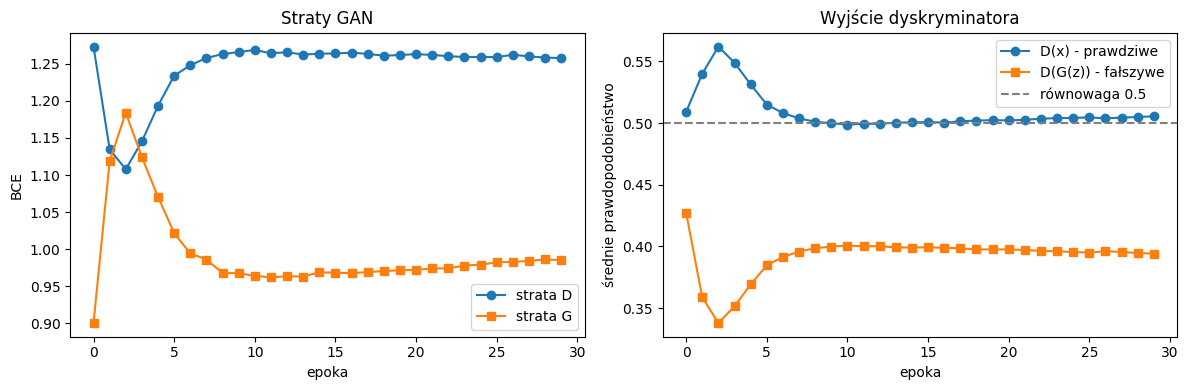

In [27]:

h = hist_gan.history
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(h["d_loss"], "o-", label="strata D"); ax[0].plot(h["g_loss"], "s-", label="strata G")
ax[0].set_xlabel("epoka"); ax[0].set_ylabel("BCE"); ax[0].set_title("Straty GAN"); ax[0].legend()
ax[1].plot(h["D_real"], "o-", label="D(x) - prawdziwe"); ax[1].plot(h["D_fake"], "s-", label="D(G(z)) - fałszywe")
ax[1].axhline(0.5, color="gray", ls="--", label="równowaga 0.5")
ax[1].set_xlabel("epoka"); ax[1].set_ylabel("średnie prawdopodobieństwo"); ax[1].set_title("Wyjście dyskryminatora")
ax[1].legend(); plt.tight_layout(); plt.show()

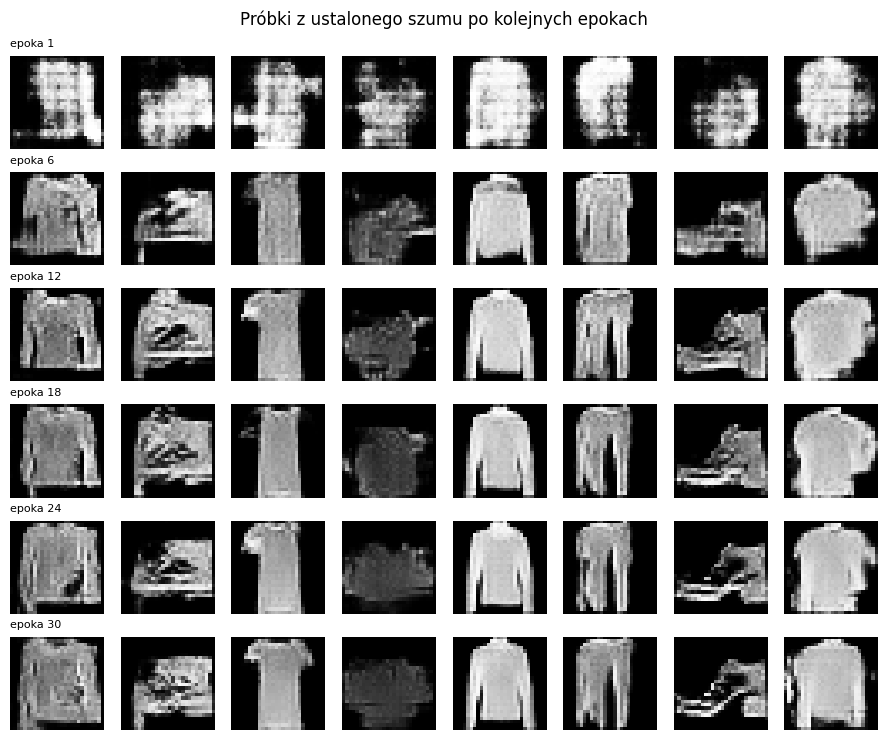

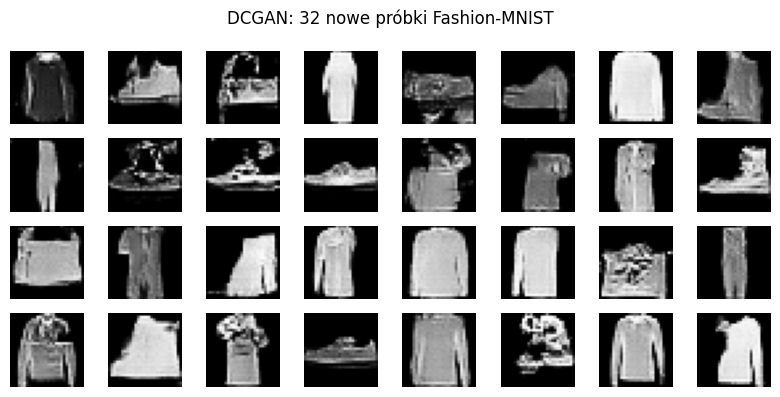

In [28]:

epoki_do_pokazu = sorted(set(np.linspace(0, len(monitor.migawki) - 1, min(6, len(monitor.migawki))).astype(int)))
fig, axes = plt.subplots(len(epoki_do_pokazu), 8, figsize=(9, 1.25 * len(epoki_do_pokazu)))
axes = np.atleast_2d(axes)
for r, e in enumerate(epoki_do_pokazu):
    for c in range(8):
        axes[r, c].imshow(monitor.migawki[e][c, :, :, 0], cmap="gray", vmin=-1, vmax=1); axes[r, c].axis("off")
    axes[r, 0].set_title(f"epoka {e + 1}", fontsize=8, loc="left")
fig.suptitle("Próbki z ustalonego szumu po kolejnych epokach"); plt.tight_layout(); plt.show()

plansza(ops.convert_to_numpy(G(keras.random.normal((32, LATENT_GAN), seed=7), training=False)), 4, 8,
        "DCGAN: 32 nowe próbki Fashion-MNIST", zakres=(-1, 1))

### Zadanie 3.3 - interpolacja w przestrzeni szumu GAN (liniowa i sferyczna)

Przestrzeń $\mathbf{z}$ GAN-a też jest ciągła. Wylosuj dwa wektory $\mathbf{z}_a, \mathbf{z}_b$ i wygeneruj 10 obrazów pośrednich na dwa sposoby:
1. **liniowo:** $\mathbf{z}_t = (1-t)\mathbf{z}_a + t\mathbf{z}_b$,
2. **sferycznie (slerp):** $\mathbf{z}_t = \frac{\sin((1-t)\Omega)}{\sin\Omega}\mathbf{z}_a + \frac{\sin(t\Omega)}{\sin\Omega}\mathbf{z}_b$, gdzie $\cos\Omega = \frac{\mathbf{z}_a\cdot\mathbf{z}_b}{\lVert\mathbf{z}_a\rVert\lVert\mathbf{z}_b\rVert}$.

Dlaczego slerp? W wysokim wymiarze prawie cała masa $\mathcal{N}(0, I)$ leży na "skorupie" o promieniu $\approx\sqrt{d}$. Środek odcinka między dwoma losowymi punktami ma normę ok. $\sqrt{d/2}$ - to obszar, którego generator prawie nie widział podczas treningu. Slerp idzie po skorupie.

Zapisz normy pośrednich wektorów (`normy_lin`, `normy_slerp`) i narysuj je na wykresie oraz oba wiersze obrazów.

**Kryteria sukcesu:** norma interpolacji liniowej "zapada się" w środku (ok. $0.71\sqrt{d}$), slerp utrzymuje ją ok. $\sqrt{d}$.

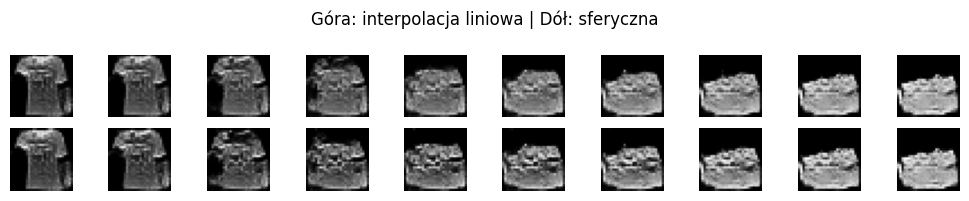

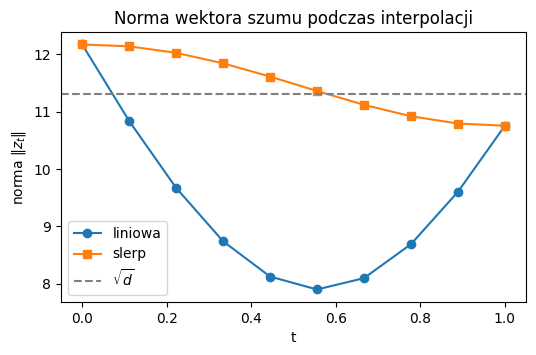

In [29]:
def slerp(za, zb, t):

    omega = np.arccos(np.clip(np.dot(za, zb) / (np.linalg.norm(za) * np.linalg.norm(zb)), -1, 1))
    if np.isclose(omega, 0):
        return (1 - t) * za + t * zb
    return np.sin((1 - t) * omega) / np.sin(omega) * za + np.sin(t * omega) / np.sin(omega) * zb

rng = np.random.default_rng(3)
z_a, z_b = rng.normal(size=LATENT_GAN), rng.normal(size=LATENT_GAN)
ts = np.linspace(0, 1, 10)
normy_lin, normy_slerp = [], []
z_lin=np.asarray([(1-t)*z_a+t*z_b for t in ts],dtype=np.float32)
z_slerp=np.asarray([slerp(z_a,z_b,t) for t in ts],dtype=np.float32)
normy_lin=np.linalg.norm(z_lin,axis=1).tolist()
normy_slerp=np.linalg.norm(z_slerp,axis=1).tolist()
ob_lin=ops.convert_to_numpy(G(z_lin,training=False))
ob_slerp=ops.convert_to_numpy(G(z_slerp,training=False))
plansza(np.concatenate([ob_lin,ob_slerp]),2,10,
        "Góra: interpolacja liniowa | Dół: sferyczna",zakres=(-1,1))
plt.figure(figsize=(6, 3.5))
plt.plot(ts, normy_lin, "o-", label="liniowa"); plt.plot(ts, normy_slerp, "s-", label="slerp")
plt.axhline(np.sqrt(LATENT_GAN), color="gray", ls="--", label="$\\sqrt{d}$")
plt.xlabel("t"); plt.ylabel("norma $\\|z_t\\|$"); plt.title("Norma wektora szumu podczas interpolacji"); plt.legend(); plt.show()

### Zadanie 3.4 - czy mamy mode collapse? Pomiar różnorodności klasyfikatorem

Wzrokowa ocena jest subiektywna. Prosty, ilościowy sposób (idea zbliżona do *Inception Score*): wytrenuj klasyfikator Fashion-MNIST i sprawdź, **jak rozkładają się klasy wygenerowanych obrazów**. Zdrowy GAN generuje wszystkie 10 klas mniej więcej po równo; przy mode collapse dominuje kilka klas.

1. Klasyfikator (gotowy kod poniżej) - uruchom i sprawdź dokładność na teście.
2. Wygeneruj `N_GEN` obrazów, sklasyfikuj je, policz histogram klas i **znormalizowaną entropię** rozkładu klas $H = -\frac{1}{\log 10}\sum_c p_c \log p_c$ ($H=1$ - idealnie równo, $H\to0$ - jedna klasa). Zapisz w `entropia_gen`.
3. Policz średnią maksymalną pewność klasyfikatora na próbkach (`pewnosc_gen`) - niska oznacza obrazy "niepodobne do niczego".
4. Porównaj z tymi samymi miarami dla prawdziwych obrazów testowych (`entropia_real`, `pewnosc_real`).

In [30]:

wej = keras.Input(shape=(28, 28, 1))
h = layers.Conv2D(32, 3, activation="relu", padding="same")(wej)
h = layers.MaxPooling2D()(h)
h = layers.Conv2D(64, 3, activation="relu", padding="same")(h)
h = layers.MaxPooling2D()(h)
h = layers.Flatten()(h)
cechy = layers.Dense(64, activation="relu", name="cechy")(h)
wyj = layers.Dense(10, activation="softmax")(layers.Dropout(0.3)(cechy))
klasyfikator = keras.Model(wej, wyj, name="klasyfikator_fashion")
klasyfikator.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
klasyfikator.fit(x_fash, y_fash, epochs=1 if SZYBKI_TRYB else 5, batch_size=128, verbose=2)
print("Dokładność na teście:", round(klasyfikator.evaluate(x_fash_te, y_fash_te, verbose=0)[1], 3))

Epoch 1/5
469/469 - 11s - 23ms/step - accuracy: 0.7930 - loss: 0.5947
Epoch 2/5
469/469 - 2s - 5ms/step - accuracy: 0.8679 - loss: 0.3743
Epoch 3/5
469/469 - 2s - 5ms/step - accuracy: 0.8876 - loss: 0.3180
Epoch 4/5
469/469 - 2s - 5ms/step - accuracy: 0.8981 - loss: 0.2848
Epoch 5/5
469/469 - 2s - 5ms/step - accuracy: 0.9074 - loss: 0.2601
Dokładność na teście: 0.905


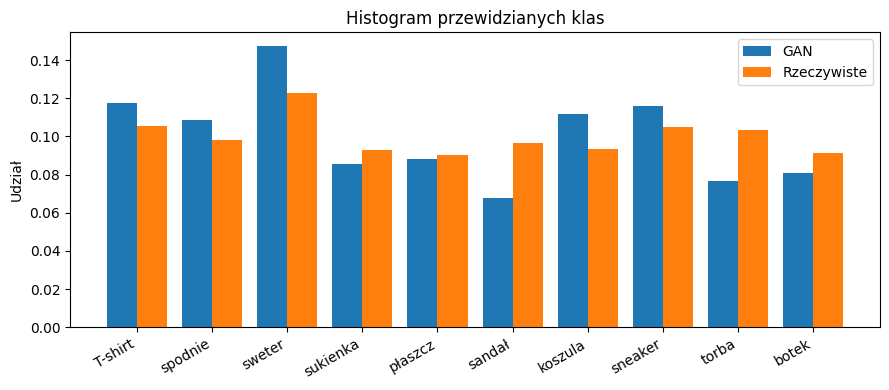

Entropia: GAN 0.9886787066968472 | prawdziwe 0.9981587568912819
Średnia pewność: GAN 0.7844741344451904 | prawdziwe 0.9135378003120422


In [31]:
N_GEN = 1000 if SZYBKI_TRYB else 5000
entropia_gen = pewnosc_gen = entropia_real = pewnosc_real = None

def entropia_znorm(p):

    p = p[p > 0]
    return float(-(p * np.log(p)).sum() / np.log(10))

z_gen=keras.random.normal((N_GEN,LATENT_GAN),seed=SEED)
obrazy_gen=ops.convert_to_numpy(G(z_gen,training=False))
p_gen=klasyfikator.predict(obrazy_gen,batch_size=256,verbose=0)
p_real=klasyfikator.predict(x_fash_te[:N_GEN],batch_size=256,verbose=0)
rozk_gen=np.bincount(p_gen.argmax(axis=1),minlength=10)/len(p_gen)
rozk_real=np.bincount(p_real.argmax(axis=1),minlength=10)/len(p_real)
entropia_gen=entropia_znorm(rozk_gen)
entropia_real=entropia_znorm(rozk_real)
pewnosc_gen=float(p_gen.max(axis=1).mean())
pewnosc_real=float(p_real.max(axis=1).mean())
plt.figure(figsize=(9,4));x=np.arange(10)
plt.bar(x-.2,rozk_gen,width=.4,label="GAN")
plt.bar(x+.2,rozk_real,width=.4,label="Rzeczywiste")
plt.xticks(x,KLASY_FASHION,rotation=30,ha="right")
plt.title("Histogram przewidzianych klas");plt.ylabel("Udział");plt.legend();plt.tight_layout();plt.show()
print(f"Entropia: GAN {entropia_gen} | prawdziwe {entropia_real}")
print(f"Średnia pewność: GAN {pewnosc_gen} | prawdziwe {pewnosc_real}")

### Czy GAN zapamiętał dane treningowe? Test najbliższego sąsiada

Jeśli generator kopiuje obrazy treningowe, każda próbka ma "bliźniaka" w zbiorze uczącym. Dla kilku próbek szukamy najbliższego obrazu treningowego (odległość euklidesowa w przestrzeni cech klasyfikatora - bardziej semantyczna niż piksele) i wyświetlamy pary. Podobne, ale **nie identyczne** pary to dobry znak - model uogólnia.

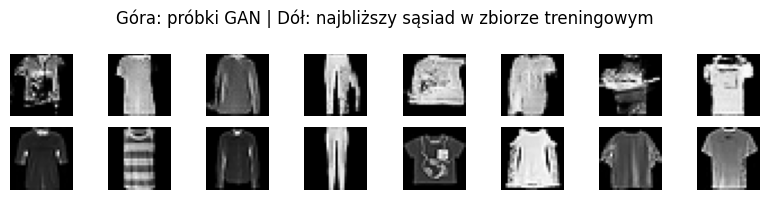

odległości do najbliższego sąsiada: [3.35 4.37 2.2  5.4  6.09 3.39 4.67 3.87]


In [32]:
from sklearn.neighbors import NearestNeighbors
ekstr_nn = keras.Model(klasyfikator.input, klasyfikator.get_layer("cechy").output)
f_tr = ekstr_nn.predict(x_fash, verbose=0)
x_pr = ops.convert_to_numpy(G(keras.random.normal((8, LATENT_GAN), seed=21), training=False))
nn_model = NearestNeighbors(n_neighbors=1).fit(f_tr)
odl, idx = nn_model.kneighbors(ekstr_nn.predict(x_pr, verbose=0))
plansza(np.concatenate([x_pr, x_fash[idx[:, 0]]]), 2, 8,
        "Góra: próbki GAN | Dół: najbliższy sąsiad w zbiorze treningowym", zakres=(-1, 1))
print("odległości do najbliższego sąsiada:", odl[:, 0].round(2))

### Mode collapse i niestabilność - jak rozpoznać i co robić

| Objaw | Co widać | Typowe leki |
|---|---|---|
| Mode collapse | próbki prawie identyczne, niska entropia klas | minibatch discrimination, unrolled GAN, WGAN-GP, mniejsze lr G, restart |
| D wygrywa | `d_loss` -> 0, `D_fake` -> 0, `g_loss` rośnie | label smoothing, Dropout / szum w D, mniejsze lr D, mniej kroków D |
| G "oszukuje" słabego D | `D_fake` > 0.5 długo, obrazy słabe | większa pojemność D, więcej kroków D |
| Oscylacje | jakość próbek rośnie i spada | mniejsze lr, Adam z $\beta_1 = 0.5$, EMA wag G, zapis checkpointów i wybór najlepszego |

Zaawansowane warianty (W5): **WGAN / WGAN-GP** (odległość Wassersteina zamiast BCE - stabilniejsze gradienty), **spectral normalization** w D, **conditional GAN** (generowanie zadanej klasy), **StyleGAN**. Miara jakości: **FID** - odległość Frécheta między rozkładami cech (zwykle z sieci Inception) prawdziwych i wygenerowanych obrazów; im niższy, tym lepiej.

## 4. *(Opcjonalnie)* Ten sam GAN w PyTorch - wersja skrócona

Ta sekcja jest dla chętnych lub do domu. Pokazuje, że GAN to w istocie **dwie przeplatające się pętle optymalizacji**, które w PyTorch piszemy jawnie (W3). Architektura jest odpowiednikiem naszego DCGAN; różnice notacyjne:
- obrazy w formacie **NCHW** `(batch, 1, 28, 28)` (Keras: NHWC),
- `nn.ConvTranspose2d(k=4, s=2, p=1)` podwaja rozdzielczość: $H_{out} = (H-1)\cdot2 - 2\cdot1 + 4 = 2H$,
- `nn.BCEWithLogitsLoss` = sigmoid + BCE (odpowiednik `from_logits=True`),
- **`fake.detach()`** w kroku D - odcinamy graf, żeby gradient straty D nie płynął do G,
- `opt.zero_grad()` przed każdym `backward()`, bo PyTorch domyślnie **akumuluje** gradienty.

### Zadanie 4.1 *(opcjonalne)* - pętla treningowa GAN w PyTorch

Uzupełnij ciało pętli po batchach:
1. **Krok D:** `fake = G_t(z)`; `loss_D = kryterium(D_t(real), 0.9·jedynki) + kryterium(D_t(fake.detach()), zera)`; `opt_D.zero_grad()`, `loss_D.backward()`, `opt_D.step()`.
2. **Krok G:** `loss_G = kryterium(D_t(fake), jedynki)`; `opt_G.zero_grad()`, `loss_G.backward()`, `opt_G.step()`.
3. Dopisz `loss_D.item()` i `loss_G.item()` do list `straty_D`, `straty_G`.

**Kryteria sukcesu:** straty w podobnym zakresie jak w Keras; po `EPOKI_TORCH` epokach (pełny tryb) widać rozpoznawalne ubrania.

**Pytanie:** co by się stało bez `.detach()`? (Podpowiedź: `loss_D.backward()` policzyłby gradienty także dla G i zużył graf obliczeniowy - drugi `backward` dla G zgłosiłby błąd lub G uczyłby się w złym kierunku przy kolejnym kroku.)

## 5. Dalej niż GAN: modele dyfuzyjne i etyka (dyskusja, ok. 10 min)

**Modele dyfuzyjne (W5, zarys).** Proces "w przód" stopniowo dodaje szum gaussowski do obrazu przez $T$ kroków, aż powstanie czysty szum. Sieć (zwykle U-Net) uczy się **odwracać jeden krok** - przewidywać dodany szum $\boldsymbol\epsilon_\theta(\mathbf{x}_t, t)$, strata to proste MSE. Generowanie = start z szumu i $T$ kroków odszumiania. Związki z naszymi zajęciami:
- to uogólnienie **autoenkodera odszumiającego** z Lab 6 na wiele poziomów szumu,
- formalnie to hierarchiczny **VAE** z ustalonym enkoderem (procesem zaszumiania),
- w porównaniu z GAN: trening stabilny (jedna strata MSE, brak gry), wysoka różnorodność (brak mode collapse), ale wolne próbkowanie (wiele kroków).

**Etyka (UGŁ_K01).** Modele generatywne umożliwiają tworzenie **deepfake'ów** (podszywanie się pod osoby, dezinformacja, nadużycia wizerunku), mogą odtwarzać dane treningowe (prywatność, prawa autorskie) i powielać uprzedzenia obecne w danych. Odpowiedzi: znakowanie treści (watermarking, C2PA), detektory, przepisy (AI Act w UE - obowiązek oznaczania treści syntetycznych), dokumentowanie zbiorów i modeli.

**Pytania do dyskusji:**
1. Jak sprawdzić, czy nasz GAN nie "zapamiętał" obrazów treningowych? (wskazówka: najbliższy sąsiad w zbiorze treningowym)
2. Czy publikacja wytrenowanego generatora twarzy powinna wymagać ograniczeń? Jakich?

## 6. Sprawozdanie końcowe z laboratorium - instrukcja

Zgodnie z kartą przedmiotu ocena z laboratorium obejmuje **aktywność na zajęciach, wykonanie ćwiczeń i przesłanie sprawozdania podsumowującego po ostatnich zajęciach**. Ocena końcowa z przedmiotu = 60% kolokwium + 40% laboratorium (aktywność + sprawozdanie); obie części muszą być zaliczone pozytywnie.

### Termin i forma
- **Jedno sprawozdanie indywidualne** w formacie **PDF** (zalecane 10-15 stron bez załączników), przesłane w terminie i kanałem podanym przez prowadzącą.
- Do sprawozdania dołącz **link do notebooka Colab** z mini-projektem (udostępnienie "każdy, kto ma link - przeglądający") albo plik `.ipynb` **z zapisanymi wynikami komórek**.
- Nazwa pliku: `UG_Sprawozdanie_Nazwisko_Imie_nrIndeksu.pdf`.

### Wymagana struktura
1. **Strona tytułowa:** imię i nazwisko, nr indeksu, kierunek i semestr, nazwa kursu, prowadząca, data.
2. **Wybrane wyniki z Lab 3-7** (ok. 1-2 strony na laboratorium). W każdym laboratorium sekcja "Do sprawozdania końcowego" mówi, co pokazać. Każdy wykres musi mieć tytuł, opisane osie, legendę i **1-3 zdania interpretacji** (co widać, dlaczego, co z tego wynika).
3. **Mini-projekt - własny eksperyment** (najważniejsza część, ok. 4-6 stron):
   - **problem i zbiór danych** - wyłącznie zbiory używane na kursie (`keras.datasets`: MNIST, Fashion-MNIST, CIFAR-10; `sklearn.datasets`; `torchvision` MNIST/FashionMNIST) lub inne publiczne po uzgodnieniu z prowadzącą,
   - **hipoteza** sformułowana przed eksperymentem, w postaci sprawdzalnej, np. *"Autoenkoder konwolucyjny wykryje anomalie (klasa 'sandał') w Fashion-MNIST z wyższym ROC-AUC niż autoenkoder gęsty o tej samej liczbie parametrów"* (**UGŁ_U01**),
   - **metodyka** - architektura(y), hiperparametry, podział danych, metryki, baseline (np. model klasyczny lub prostszy model sieciowy), liczba powtórzeń (seedy),
   - **wyniki** - tabela i wykresy, najlepiej średnia ± odchylenie standardowe z co najmniej 3 uruchomień,
   - **weryfikacja hipotezy** - potwierdzona / odrzucona / częściowo, z uzasadnieniem liczbowym,
   - **propozycja usprawnienia** opartego na istniejących bibliotekach (np. inna architektura, regularyzacja, augmentacja, transfer learning, tuning KerasTuner/Optuna), **najlepiej sprawdzona eksperymentalnie** (**UGŁ_U02**).
4. **Wnioski i ograniczenia** (0,5-1 strona): co się udało, czego nie wiemy, co zrobiłbyś dalej.
5. **Bibliografia:** co najmniej 3 pozycje, w tym min. 1 z literatury przedmiotu i min. 1 artykuł naukowy lub dokumentacja (keras.io, pytorch.org) - **UGŁ_K01**.
6. **Oświadczenie o samodzielności** i informacja o użyciu narzędzi AI (do czego, w jakim zakresie). Kod i tekst muszą być rozumiane przez autora - prowadząca może poprosić o krótkie omówienie.

### Przykładowe tematy mini-projektu
- VAE vs AE vs PCA jako ekstraktor cech dla k-means na Fashion-MNIST (ARI/NMI).
- Wpływ $\beta$ i wymiaru latentu VAE na jakość rekonstrukcji i różnorodność próbek.
- DCGAN vs DCGAN z innymi technikami stabilizacji (label smoothing, spectral norm, różne lr D i G) - porównanie entropii klas / FID-lite.
- Transfer learning vs CNN od zera na podzbiorach CIFAR-10 różnej wielkości (krzywa uczenia w funkcji liczby danych).
- Sieć MLP (PyTorch) vs HistGradientBoosting na `fetch_california_housing` lub `load_breast_cancer` z walidacją krzyżową i analizą wycieku danych.

### Checklista przed wysłaniem sprawozdania

**Forma**
- [ ] PDF z poprawną nazwą pliku, strona tytułowa kompletna
- [ ] link do notebooka Colab działa (sprawdzone w trybie incognito) lub dołączony `.ipynb` z wynikami
- [ ] notebook wykonuje się od początku do końca (Środowisko wykonawcze -> Uruchom wszystko) bez błędów
- [ ] seedy ustawione, wersje bibliotek podane (komórka poniżej)

**Treść z Lab 3-7**
- [ ] z każdego laboratorium 3-7 co najmniej jeden wynik zgodny z sekcją "Do sprawozdania końcowego"
- [ ] wszystkie wykresy mają tytuł, opisy osi, legendę i interpretację w tekście
- [ ] liczby w tabelach mają jednostki / nazwy metryk i rozsądną liczbę cyfr znaczących

**Mini-projekt**
- [ ] hipoteza sformułowana wprost, **przed** opisem wyników
- [ ] jest baseline i uczciwe porównanie (ten sam podział danych, podobny budżet treningu)
- [ ] brak wycieku danych: skalowanie / PCA / wybór progu dopasowane tylko na zbiorze treningowym (walidacyjnym)
- [ ] zbiór testowy użyty tylko do końcowej oceny, nie do wyboru hiperparametrów
- [ ] wyniki z kilku uruchomień (średnia ± odch. std.) lub uzasadnienie, dlaczego jedno
- [ ] jasna odpowiedź: hipoteza potwierdzona / odrzucona / częściowo - z liczbami
- [ ] propozycja usprawnienia (UGŁ_U02), najlepiej sprawdzona eksperymentalnie

**Na koniec**
- [ ] wnioski i ograniczenia
- [ ] bibliografia (min. 3 pozycje, cytowania w tekście)
- [ ] oświadczenie o samodzielności i o użyciu narzędzi AI

In [34]:
import platform, sklearn, torch
import tensorflow as tf
import keras
import numpy as np
import pandas as pd

SEED = 42
SZYBKI_TRYB = False
print("Python       :", platform.python_version())
print("TensorFlow   :", tf.__version__, "| Keras:", keras.__version__, "| backend:", keras.backend.backend())
print("PyTorch      :", torch.__version__, "| CUDA:", torch.cuda.is_available())
print("scikit-learn :", sklearn.__version__, "| NumPy:", np.__version__, "| pandas:", pd.__version__)
print("GPU          :", [g.name for g in tf.config.list_physical_devices("GPU")] or "brak")
print("SEED         :", SEED, "| SZYBKI_TRYB:", SZYBKI_TRYB)

Python       : 3.13.15
TensorFlow   : 2.21.0 | Keras: 3.13.2 | backend: tensorflow
PyTorch      : 2.11.0+cu130 | CUDA: True
scikit-learn : 1.6.1 | NumPy: 2.1.3 | pandas: 2.2.3
GPU          : ['/physical_device:GPU:0']
SEED         : 42 | SZYBKI_TRYB: False


In [35]:

def raport_powtorzen(wyniki, nazwa="metryka"):

    w = np.asarray(wyniki, dtype=float)
    return f"{nazwa} = {w.mean():.3f} ± {w.std(ddof=1) if len(w) > 1 else 0:.3f} (n = {len(w)})"


print(raport_powtorzen([0.871, 0.884, 0.879], "ROC-AUC"))

ROC-AUC = 0.878 ± 0.007 (n = 3)


## Pytania kontrolne

1. Jakie dwa składniki ma strata VAE i co by się stało, gdyby usunąć każdy z nich?
2. Na czym polega trik reparametryzacji i dlaczego jest potrzebny?
3. Dlaczego enkoder VAE zwraca $\log\sigma^2$, a nie $\sigma$?
4. Dlaczego próbki z VAE są zwykle bardziej rozmyte niż z GAN?
5. Zapisz funkcję celu minimax GAN. Czym jest *non-saturating loss* generatora i dlaczego się go używa?
6. Dlaczego w kroku dyskryminatora w PyTorch używamy `fake.detach()`, a w Keras liczymy gradient tylko po `discriminator.trainable_weights`?
7. Czym jest mode collapse i jak można go wykryć ilościowo? Jakie ograniczenia ma miara oparta na rozkładzie klas?
8. Dlaczego wartości strat G i D nie są dobrą miarą jakości wygenerowanych obrazów? Co stosujemy zamiast nich?

### Odpowiedzi na pytania kontrolne

**1. Dwa składniki straty VAE.** Strata zawiera **błąd rekonstrukcji** (jak dobrze dekoder odtwarza dane) oraz **KL divergence** między rozkładem latentnym $q_\phi(z\mid x)$ a priorem $p(z)$ (zwykle $\mathcal N(0,I)$). Bez rekonstrukcji model nie musi zachowywać informacji o wejściu. Bez KL latent może przyjąć dowolne, nieregularne rozmieszczenie — rekonstrukcje mogą być dobre, ale **próbkowanie z prioru** często generuje słabe wyniki.

**2. Reparametryzacja.** Zamiast bezpośrednio losować $z\sim\mathcal N(\mu,\sigma^2)$ zapisujemy $z=\mu+\sigma\odot\varepsilon$, gdzie $\varepsilon\sim\mathcal N(0,I)$ jest losowane niezależnie od parametrów. Dzięki temu zróżniczkowalna część losowania jest deterministyczną funkcją $\mu$ i $\sigma$, a gradient może płynąć przez próbkowany latent do enkodera.

**3. Dlaczego `logvar`?** Enkoder zwraca $\log\sigma^2$, czyli logarytm **wariancji**. Ta liczba może przyjmować dowolną wartość rzeczywistą, natomiast wariancję otrzymujemy jako $\exp(\mathrm{logvar})>0$. Wygodne są też wzory $\sigma=\exp(0.5\,\mathrm{logvar})$ oraz analityczny KL dla rozkładu normalnego; takie parametryzowanie pomaga w optymalizacji, choć ekstremalne wartości nadal mogą sprawiać problemy numeryczne.

**4. Rozmycie w VAE vs GAN.** Przy typowej funkcji rekonstrukcji piksel po pikselu (MSE lub BCE) i niepewności co do szczegółów dekoder VAE bywa skłaniany do odtwarzania **uśrednionych struktur**, co wygląda jak rozmycie. GAN dzięki dyskryminatorowi silniej premiuje **realistyczne, ostre szczegóły**. Nie jest to uniwersalna reguła dla każdej architektury i funkcji straty.

**5. Cel GAN i non-saturating generator.** Klasyczny minimax to
$$\min_G\max_D\;\mathbb E_{x\sim p_{data}}[\log D(x)]+\mathbb E_{z\sim p(z)}[\log(1-D(G(z)))].$$
W praktyce generator często minimalizuje **non-saturating loss** $-\mathbb E_z[\log D(G(z))]$, zamiast $\mathbb E_z[\log(1-D(G(z)))]$. Daje to silniejszy sygnał uczenia, gdy dyskryminator z łatwością odrzuca generowane obrazy.

**6. `fake.detach()` / lista trenowanych wag w Keras.** W kroku dyskryminatora `fake.detach()` odcina graf prowadzący z wygenerowanych obrazów do generatora, żeby podczas `backward()` **nie liczyć gradientów generatora**. W Keras można zbudować stratę dyskryminatora, a następnie poprosić `GradientTape` tylko o pochodne względem `discriminator.trainable_weights` i aktualizować wyłącznie te wagi. Generator ma osobny krok i osobny optymalizator.

**7. Mode collapse.** To sytuacja, gdy generator zwraca ograniczony zestaw podobnych obrazów, ignorując dużą część rzeczywistej różnorodności danych. Można badać **rozkład przewidywanych klas** wygenerowanych próbek (np. jego entropię), liczbę reprezentowanych klas oraz różnorodność w embeddingach. Ograniczenie rozkładu klas: **wysoka entropia klas nie gwarantuje różnorodności wewnątrz każdej klasy** — generator może produkować jeden niemal identyczny przykład dla każdej klasy. Wynik zależy też od jakości klasyfikatora.

**8. Dlaczego same straty GAN nie mierzą jakości obrazów?** Generator i dyskryminator uczą się przeciwko sobie, więc wartości ich strat zależą od **aktualnej siły przeciwnika**, a nie tylko od realizmu czy różnorodności obrazów. Nie muszą maleć monotonicznie. Zamiast nich sprawdzamy **próbki wizualnie**, **FID** (lub szkolne FID-lite), czasem **Inception Score**, a także miary różnorodności/mode collapse. Metryki automatyczne również mają ograniczenia.


## Podsumowanie - co warto zapamiętać

**Z tego laboratorium**
- **VAE** = AE z probabilistycznym enkoderem; strata = rekonstrukcja (suma po pikselach) + $\beta\cdot$KL; **trik reparametryzacji** $z = \mu + \sigma\epsilon$; przestrzeń latentna jest regularna - można z niej losować i interpolować.
- $\beta$ steruje kompromisem: regularność latentu vs jakość rekonstrukcji.
- **GAN** = gra G vs D; trenujemy naprzemiennie, z gradientami tylko po wagach właściwej sieci; G używa *non-saturating loss*; zasady DCGAN (stride, BN w G, LeakyReLU w D, tanh, Adam 2e-4/0.5).
- **Straty GAN nie mierzą jakości** - monitorujemy próbki z ustalonego szumu, $D(x)$, $D(G(z))$, różnorodność (entropia klas, FID).
- W Keras 3 własny `train_step`: `tf.GradientTape`, `keras.ops`, `keras.random` z `SeedGenerator`, metryki-śledzące zwracane przez właściwość `metrics`, `super().compile()`.
- W PyTorch: `zero_grad -> backward -> step`, `fake.detach()` w kroku D, `eval()` + `no_grad()` przy generowaniu.

**Z całego kursu (W1-W5, L1-L7)**
- DL = modelowanie (architektura) + optymalizacja (strata, gradient, optymalizator) - od regresji liniowej z gradientem liczonym ręcznie (L1) do modeli generatywnych (L7).
- Komponenty: warstwy gęste, splotowe, pooling, transponowane, normalizacja, Dropout, residua - dobór do danych i zadania.
- Rzetelność: poprawny podział danych, brak wycieku, baseline, kilka uruchomień, właściwe metryki.
- Uczenie nienadzorowane: PCA/SVD/LDA, autoenkodery, klasteryzacja w latencie, VAE, GAN, dyfuzja.

## Do sprawozdania końcowego

Z tego laboratorium umieść w sprawozdaniu:
1. Przestrzeń latentną VAE (wykres `z_mean`) i siatkę wygenerowanych cyfr z interpretacją (czy przestrzeń jest regularna? gdzie leżą które cyfry?).
2. Wyniki eksperymentu z $\beta$ (Zadanie 2.4) - tabela + **hipoteza i jej weryfikacja**.
3. Krzywe strat GAN, wykres $D(x)$ / $D(G(z))$ oraz planszę ewolucji próbek po epokach - z komentarzem, dlaczego straty nie mówią o jakości.
4. Ocenę różnorodności (entropia klas, pewność klasyfikatora) i odpowiedź: czy wystąpił mode collapse?
5. *(Opcjonalnie)* porównanie implementacji Keras i PyTorch (czas epoki, wygląd próbek) lub wynik zadania dodatkowego (FID-lite) - dobry punkt wyjścia do mini-projektu.

## Zadanie dodatkowe (dla chętnych) - "FID-lite": odległość Frécheta w przestrzeni cech klasyfikatora

**FID** (Heusel i in., 2017) modeluje cechy obrazów prawdziwych i wygenerowanych jako rozkłady normalne $\mathcal{N}(\mu_r, \Sigma_r)$ i $\mathcal{N}(\mu_g, \Sigma_g)$ i liczy odległość Frécheta:
$$\text{FD} = \lVert\mu_r - \mu_g\rVert^2 + \operatorname{Tr}\left(\Sigma_r + \Sigma_g - 2(\Sigma_r\Sigma_g)^{1/2}\right).$$
Oryginalny FID używa cech sieci Inception-v3 (2048 wymiarów). My użyjemy 64-wymiarowej warstwy `cechy` naszego klasyfikatora Fashion-MNIST - wartości nie są porównywalne z FID z literatury, ale ranking modeli ma sens.

1. Zbuduj model `ekstraktor` zwracający wyjście warstwy `cechy`.
2. Napisz `frechet(f1, f2)` (użyj `scipy.linalg.sqrtm`, odrzuć część urojoną).
3. Policz FD dla: (a) dwóch rozłącznych połówek prawdziwych obrazów testowych (punkt odniesienia ~0), (b) próbek z wytrenowanego `G`, (c) próbek z **niewytrenowanego** generatora, (d) próbek z generatora PyTorch (jeśli trenowałeś). Zapisz w słowniku `fd`.

**Kryteria sukcesu:** FD(a) < FD(b) << FD(c).